# GATE (Listmode Reconstruction; Without Time of Flight)

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("PET/GATE-mMR-BrainInWater")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("PET/GATE-mMR-BrainInWater")

PET/GATE-mMR-BrainInWater: already downloaded


In [2]:
from __future__ import annotations
import torch
import numpy as np
import pytomography
from pytomography.metadata import ObjectMeta
from pytomography.metadata.PET import PETLMProjMeta
from pytomography.projectors.PET import PETLMSystemMatrix
from pytomography.algorithms import OSEM
from pytomography import io
from pytomography.likelihoods import PoissonLogLikelihood
from pytomography.transforms.shared import GaussianFilter
import matplotlib.pyplot as plt
from pytomography.utils import sss
import gc

## How much memory this needs

Set `RAM_GB` to the memory this tutorial may use, and pass it to `pytomography.set_memory_budget`. The steps that go through all 411 million crystal pairs of the scanner (the sensitivity image) and the scatter estimate then work in blocks that fit. Each reconstruction and the scatter estimate print their estimates before they run (`estimate_memory`). The tutorial peaks at about 20 GB (measured on Windows), and needs about that whatever `RAM_GB` is (the same with `RAM_GB = 12`), so it does not fit in 16 GB: the events, their randoms, scatter and sensitivity, and the normalization weights of every crystal pair are held whole, which the budget does not split yet. The results do not depend on the budget.

In [3]:
RAM_GB = 25 # memory (RAM) this tutorial may use, in GB; it needs about 20 GB however low this is
pytomography.set_memory_budget(RAM_GB)

Reading the ROOT files takes a few minutes for each kind of coincidence, so the reader below keeps each result in `OUTPUT`, and later runs of this tutorial load it from there:

In [4]:
# The first run reads the ROOT files and caches each result in OUTPUT; later runs load the cache.
# Set this to True to recompute everything.
LOAD_FROM_ROOT = False

`io.PET.read_gate` reads the simulation: the scanner from its GATE macro, and the coincidences from its 54 ROOT files. It returns the events (pairs of crystal numbers, and a TOF bin when asked for), the object grid placed in the patient, and the projection metadata, whose `info` describes the scanner for every PET function in PyTomography. GATE's world has no patient in it; the dataset registry records how the phantom sat in it, and `read_gate` uses that for this dataset, so the images line up with the phantom's MR.

In [5]:
path = DATA / 'PET' / 'GATE-mMR-BrainInWater'
macro = path / 'mMR_Geometry.mac'  # the scanner, as the simulation's GATE macro describes it
paths = [path / 'simple_phantom' / f'mMR_voxBrain_withSimplePhantom_{i}.root' for i in range(1, 55)]  # its 54 runs


def read_gate(events, tof_meta=None, normalization=None):
    """io.PET.read_gate for one kind of coincidence: (events, object_meta, proj_meta). Reading the 54 ROOT files takes
    a few minutes, so the first run keeps the result in OUTPUT and later runs load it from there."""
    name = f'gate_{events}' + ('' if tof_meta is None else f'_tof{tof_meta.num_bins}') + ('' if normalization is None else '_norm')
    cache = OUTPUT / f'{name}.pt'
    if LOAD_FROM_ROOT or not cache.exists():
        # doi: the lines of response end 9 mm inside the crystals, the mean depth of interaction
        torch.save(io.PET.read_gate(paths, macro, events=events, tof_meta=tof_meta, normalization=normalization,
                                    doi=9), cache)
    return torch.load(cache, weights_only=False)


# The true coincidences (used from "Primary-Only Reconstruction" on), with the normalization weights of every crystal
# pair (below). proj_meta.info describes the scanner
detector_ids, object_meta, proj_meta = read_gate('trues', normalization=path / 'normalization_weights.npy')
info = proj_meta.info

We can look at the information of our PET scanner:

In [6]:
info

{'crystalTransNr': 8,
 'crystalAxialNr': 8,
 'submoduleTransNr': 1,
 'submoduleAxialNr': 1,
 'moduleTransNr': 1,
 'moduleAxialNr': 8,
 'rsectorTransNr': 56,
 'rsectorAxialNr': 1,
 'crystalTransSpacing': 4.0,
 'crystalAxialSpacing': 4.0,
 'submoduleTransSpacing': 0.0,
 'submoduleAxialSpacing': 0.0,
 'moduleTransSpacing': 0.0,
 'moduleAxialSpacing': 32.25,
 'rsectorAxialSpacing': 0.0,
 'radius': 337.0,
 'doi': 9.0,
 'crystal_length': 20.0,
 'min_rsector_difference': 0,
 'rsector0_angle': 0.0,
 'transaxial_direction': 1,
 'axial_direction': -1,
 'energy_window_low': None,
 'energy_window_high': None,
 'energy_resolution': None,
 'NrCrystalsPerRing': 448,
 'NrRings': 64}

## Normalization Correction

In PET imaging, each detector crystal used in the scanner will have a different response to a uniform source due to its positioning (e.g. crystals at the end of edge of modules are different than those in the center). Adequate PET reconstruction takes this into account by first performing a calibration scan for a scanner and obtaining a normalization correction factor for each crystal pair LOR

The normalization weights corresponding to each pair of detector IDs (due to geometry/crystal orientation) come with the dataset, in `normalization_weights.npy`. `read_gate` takes them as `normalization=` and keeps them in `proj_meta.weights_sensitivity`; the 89 million pairs whose lines of response miss the calibration shell have no weight in the file (NaN), and `read_gate` sets them to 0, with a warning. They were computed from a calibration scan done using a thin cylindrical shell, with `io.PET.gate_normalization`, which computes $\eta$ from the scan's ROOT files. For this it needs

* `cylinder_radius`: The radius of the thin cylindrical shell used for calibration (318 mm)

Randoms were left out of the scan (PyTomography PR #290). The scan itself (36 ROOT files, 46 GB) is in `PET/GATE-mMR-Brain/normalization_scan`, for anyone who wants to compute the weights again.

In [7]:
# The weights come with the dataset. They were computed from the calibration scan (36 ROOT files, 46 GB, in
# PET/GATE-mMR-Brain/normalization_scan), randoms left out (PyTomography PR #290):
# normalization_weights = io.PET.gate_normalization(normalization_paths, info, cylinder_radius=318)
normalization_weights = proj_meta.weights_sensitivity  # read_gate's: one per crystal pair, in torch.combinations order

## Primary-Only Reconstruction

Before we delve into scatter/random modeling, lets get a baseline reconstruction that uses only primary events from the simulated GATE data (i.e. we will manually exclude all scatters/randoms). PyTomography selected such events when it read the ROOT data above (`events='trues'`). Obviously this is not doable for clinical data (where we don't know which events are randoms/scatters).

We reconstruct PET listmode data as follows:
* Note: in this case, our sensitivity weights only have contribution from the normalization factor $\eta$ (and not attenuation $\mu$), so we need to include the attenuation map in the system matrix to get the true sensitivity weights

In [8]:
# The reconstruction grid: 128 x 128 x 96 voxels of 2 mm, centred where read_gate placed the scanner in the patient
object_meta = object_meta.with_grid(dr=(2, 2, 2), shape=(128, 128, 96))  # mm, voxels
# The phantom's attenuation map (1/cm), an image in GATE's world: gate_image places it in the patient as read_gate
# placed the scanner, and attenuation_map puts it on the grid, in 1/mm
atten_map = io.attenuation_map(io.PET.gate_image(path / 'umap_mMR_brainSimplePhantom.hv', proj_meta, units='1/cm'),
                               object_meta)
psf_transform = GaussianFilter(3.) # 3mm gaussian blurring
# Create system matrix: read_gate's proj_meta holds the events, the scanner's info and the normalization weights
system_matrix = PETLMSystemMatrix(
    object_meta,
    proj_meta,
    obj2obj_transforms = [psf_transform],
    attenuation_map = atten_map,
    N_splits=8,
)
# Create likelihood. For listmode reconstruction, projections don't need to be provided, since all detection events are stored in proj_meta
likelihood = PoissonLogLikelihood(
    system_matrix
)
# Initialize reconstruction algorithm
recon_algorithm = OSEM(likelihood)
print(recon_algorithm.estimate_memory(n_subsets=14)) # its peak RAM and GPU memory, before it runs
# Reconstruct
recon_primaryonly = recon_algorithm(n_iters=4, n_subsets=14)

OSEM (PETLMSystemMatrix): 14 subsets, memory budget 25 GB
Peak ~ 9.9 GB RAM, 3.1 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 1.6 GB RAM, 0.9 GB GPU (events and their projector order 0.8 GPU, sensitivity weights 1.6 RAM, sensitivity and normalisation images (14) 0.1 GPU, image, update and attenuation map 0.03 GPU, projections (the data) 0.00 GPU)
  one subset at a time: 0.00 GB RAM, 0.9 GB GPU (expected counts, ratio and temporaries (one subset) 0.1 GPU, positions of the subset's events 0.04 GPU, building a subset's projector order (its first projection) 0.8 GPU)
  projector chunks: 0.00 GB RAM, 0.04 GB GPU (projector chunk 0.04 GPU)
  Python, CUDA, allocator: 5.1 GB RAM, 1.3 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 0.7 GPU, memory the allocators keep (Windows) 2.1 RAM)
To use less: 28 subsets ~ 9.2 GB RAM, 2.6 GB GPU, N_splits 16 ~ 9.8 GB RAM, 

Plot the reconstruction of primary only events:

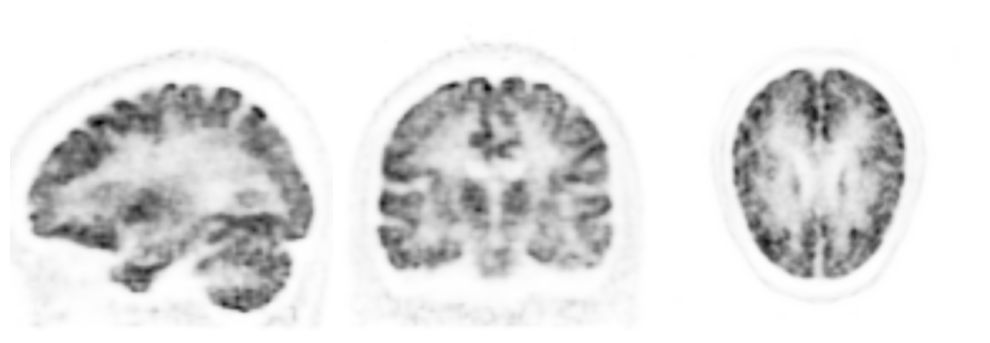

In [9]:
vmax = 0.5
cmap='Greys'
fig, ax = plt.subplots(1,3,figsize=(10,4), gridspec_kw={'wspace': 0.0})
plt.subplot(131)
plt.imshow(recon_primaryonly[50,16:-16].cpu().T, cmap=cmap, interpolation='gaussian', vmax=vmax, origin='lower')
plt.axis('off')
plt.subplot(132)
plt.imshow(recon_primaryonly[16:-16,64].cpu().T, cmap=cmap, interpolation='gaussian', vmax=vmax, origin='lower')
plt.axis('off')
plt.subplot(133)
plt.imshow(recon_primaryonly[:,:,48].cpu().T, cmap=cmap, interpolation='gaussian', vmax=vmax, origin='lower')
plt.axis('off')
fig.tight_layout()
plt.show()

## Reconstructing With Random/Scatter Estimation

For reconstruction of all events, we need to estimate boths randoms and scatters. Lets now get **all** events that were obtained in GATE:

In [10]:
# The primary-only reconstruction is done: free its events and system matrix (and PyTorch's GPU cache) before loading all the events
del detector_ids, proj_meta, system_matrix, likelihood, recon_algorithm
gc.collect()
torch.cuda.empty_cache()
detector_ids, _, _ = read_gate('prompts')

### Randoms

For random estimation via listmode, we

1. Open listmode of all delayed events
2. Convert these to a sinogram
3. Smooth the sinogram
4. Convert back to listmode


In [11]:
detector_ids_delays, _, _ = read_gate('delayeds')

In [12]:
sinogram_delays  = io.PET.listmode_to_sinogram(detector_ids_delays , info)
del detector_ids_delays # binned: the events are not needed again
sinogram_delays  = io.PET.smooth_randoms_sinogram(sinogram_delays , info, fwhm_r=20, fwhm_theta=7, fwhm_z=40)
lm_delays = io.PET.sinogram_to_listmode(detector_ids, sinogram_delays , info)

### Scatters

PyTomography estimates scatters via the single scatter simulation (SSS) algorithm (w or w/o time of flight). In order to use SSS, we need an initial reconstruction of the data (without scatter estimation). We use this reconstruction as a proxy to estimate scatter. Let's first reconstruct the data without scatter estimation (but using randoms):

In [13]:
# The same attenuation map as above, and all the events with the normalization weights
proj_meta = PETLMProjMeta(
    detector_ids,
    info,
    weights_sensitivity=normalization_weights
    )
psf_transform = GaussianFilter(3.)
system_matrix = PETLMSystemMatrix(
       object_meta,
       proj_meta,
       obj2obj_transforms = [psf_transform],
       N_splits=10,
       attenuation_map=atten_map,
)

We'll reconstruct only using randoms as an estimate. We need to pass the random listmode weights estimate divided by the sensitivty listmode weights as an additive term estimate to the likelihood function:

In [14]:
# Get additive term (without scatter term):
lm_sensitivity = system_matrix._compute_sensitivity_projection(all_ids=False)
additive_term = lm_delays / lm_sensitivity
additive_term[additive_term.isnan()] = 0 # remove NaN values
# Recon
likelihood = PoissonLogLikelihood(
        system_matrix,
        additive_term = additive_term
    )
recon_algorithm = OSEM(likelihood)
recon_without_scatter_estimation = recon_algorithm(4,14)

Now we estimate the scatter sinogram as we did before, and then convert to listmode after. Note that we still provide the sinogram of randoms (even though we're reconstructing listmode)

In [15]:
# its peak RAM and GPU memory, before it runs
print(sss.estimate_sss_memory(object_meta, proj_meta, system_matrix, sinogram_random=sinogram_delays,
                              sinogram_interring_stepsize=4, sinogram_intraring_stepsize=4))
sinogram_scatter = sss.get_sss_scatter_estimate(
    object_meta = object_meta,
    proj_meta = proj_meta,
    pet_image = recon_without_scatter_estimation,
    attenuation_image = atten_map,
    system_matrix = system_matrix,
    proj_data = None, # assumes listmode
    image_stepsize = 4,
    attenuation_cutoff = 0.004,
    sinogram_interring_stepsize = 4,
    sinogram_intraring_stepsize = 4,
    sinogram_random = sinogram_delays
    )
# Now convert to listmode
lm_scatter = io.PET.sinogram_to_listmode(proj_meta.detector_ids, sinogram_scatter, proj_meta.info)

Single scatter simulation (dense)
Peak ~ 29.7 GB RAM, 6.2 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 7.5 GB RAM, 0.01 GB GPU (PET image and attenuation map 0.01 GPU, randoms 1.6 RAM, events binned lazily 0.9 RAM, sensitivity sinogram of the sinogram system matrix 1.6 RAM, interpolated estimate (dense) and its scaled copy (host) 3.3 RAM)
  projector chunks: 3.7 GB RAM, 4.0 GB GPU (largest step on the host: scaling (20 subsets) 3.7 RAM, sparse estimate (GPU) 0.2 GPU, interpolation over angle and radius (GPU) 0.7 GPU, interpolation over the ring pairs (GPU) 1.3 GPU, scaling (20 subsets) (GPU) 1.9 GPU)
  Python, CUDA, allocator: 12.2 GB RAM, 2.1 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 1.5 GPU, memory the allocators keep (Windows) 9.2 RAM)
(plus whatever else your script keeps)


Now we can redefine our additive term to include scatter information and reconstruct:

In [16]:
additive_term = (lm_scatter + lm_delays) / lm_sensitivity
additive_term[additive_term.isnan()] = 0
likelihood = PoissonLogLikelihood(
        system_matrix,
        additive_term = additive_term
    )
recon_algorithm = OSEM(likelihood)
print(recon_algorithm.estimate_memory(n_subsets=14))
recon_lm_nontof = recon_algorithm(4,14)

OSEM (PETLMSystemMatrix): 14 subsets, memory budget 25 GB
Peak ~ 12.6 GB RAM, 5.0 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 1.6 GB RAM, 2.0 GB GPU (events and their projector order 1.4 GPU, sensitivity weights 1.6 RAM, sensitivity and normalisation images (14) 0.1 GPU, image, update and attenuation map 0.03 GPU, projections (the data) 0.00 GPU, additive term 0.5 GPU)
  one subset at a time: 0.00 GB RAM, 1.1 GB GPU (expected counts, ratio and temporaries (one subset) 0.1 GPU, positions of the subset's events 0.1 GPU, building a subset's projector order (its first projection) 0.9 GPU)
  projector chunks: 0.00 GB RAM, 0.1 GB GPU (projector chunk 0.1 GPU)
  Python, CUDA, allocator: 5.9 GB RAM, 1.8 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 1.2 GPU, memory the allocators keep (Windows) 2.9 RAM)
To use less: 28 subsets ~ 12.1 GB RAM, 4.7 GB GPU, N_sp

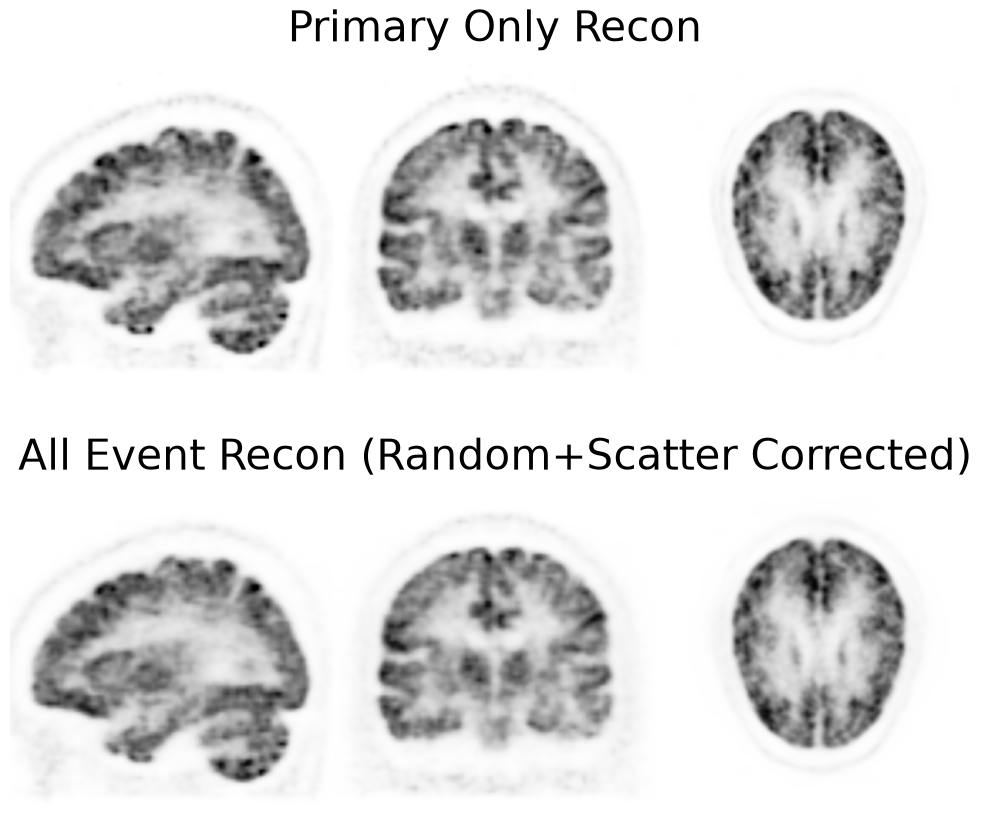

In [17]:
vmax = 0.45
cmap = 'Greys'
fig, ax = plt.subplots(2,3,figsize=(10,9), gridspec_kw={'wspace': 0.0})
plt.subplot(231)
plt.imshow(recon_primaryonly[48,16:-16].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.subplot(232)
plt.imshow(recon_primaryonly[16:-16,64].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.title('Primary Only Recon', fontsize=30)
plt.axis('off')
plt.subplot(233)
plt.imshow(recon_primaryonly[:,:,48].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.subplot(234)
plt.imshow(recon_lm_nontof[48,16:-16].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.subplot(235)
plt.imshow(recon_lm_nontof[16:-16,64].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.title('All Event Recon (Random+Scatter Corrected)', fontsize=30)
plt.subplot(236)
plt.imshow(recon_lm_nontof[:,:,48].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
fig.tight_layout()
plt.show()

## Save the images

`io.save_dicom` writes the reconstruction as a DICOM PET series, one file per slice, where `object_meta` places it. GATE data have no patient frame of their own: `read_gate` placed the grid on the phantom's MR, from the dataset registry's record of where the phantom sat in GATE's world, so it lines up with that NIfTI file in software that reads both, such as 3D Slicer.

In [18]:
saved = io.save_dicom(recon_lm_nontof, OUTPUT / 't_PETGATE_scat_lm' / 'osem', object_meta,
                      series_description='List-mode OSEM, scatter and randoms corrected', overwrite=True)

In [19]:

import json, platform, torch, pytomography
def _peak_ram_gb():
    try:
        import psutil
        m = psutil.Process().memory_info()
        if hasattr(m, "peak_pagefile"):  # Windows: peak committed memory
            return round(m.peak_pagefile / 1e9, 1)
    except ImportError:
        pass
    import resource  # ru_maxrss is in kB on Linux, bytes on macOS
    return round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (1e9 if platform.system() == "Darwin" else 1e6), 1)
_info = dict(pytomography=getattr(pytomography, "__version__", "?"), source=pytomography.__file__,
             torch=torch.__version__, python=platform.python_version(),
             gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
             peak_gpu_gb=round(torch.cuda.max_memory_allocated() / 1e9, 2) if torch.cuda.is_available() else 0.0,
             peak_ram_gb=_peak_ram_gb())
print("__PYTOMOGRAPHY_RUN__" + json.dumps(_info))


__PYTOMOGRAPHY_RUN__{"pytomography": "4.0.0rc1", "source": "C:\\Users\\lukep\\miniforge3\\envs\\pytomo-rc1\\Lib\\site-packages\\pytomography\\__init__.py", "torch": "2.14.1+cu130", "python": "3.12.16", "gpu": "NVIDIA GeForce RTX 5060 Laptop GPU", "peak_gpu_gb": 2.88, "peak_ram_gb": 19.2}
